# E6 — Contact taps and holds (Inverse3)

`e6_taps.py`. Per run, the contact metrics averaged over its taps, the stability indicators (bounces,
settling, HF force RMS above 8 Hz) and the energy balance (E < 0: the system generated energy).

In [7]:
# Runs to analyse: run directories, session files (exp/<exp>/sessions/*.txt, written by the script) or a
# folder of runs (a folder also holds retried and superseded runs). Default: the latest session file,
# which lists every condition once.
from common import latest_session

RUNS = [latest_session("e6")]
RECOMPUTE = False  # True: recompute the metrics from the data instead of reading analysis/metrics.json

In [8]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # before anything imports JAX: the GPU stays free for fr3_teleop's IK
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/exp
sys.path[:0] = [str(HERE), str(HERE.parent)]
import matplotlib.pyplot as plt  # noqa: I001
import numpy as np
import pandas as pd

import exp_metrics
import plots as P
from common import collect, load_table

%matplotlib inline
%load_ext autoreload
%autoreload 2
pd.set_option("display.precision", 3)

runs = collect(RUNS)
df = load_table(runs, exp_metrics.e6 if RECOMPUTE else None)
print(f"{len(df)} runs")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
2 runs


In [9]:
cols = [
    "run",
    "method",
    "rtt",
    "contacts",
    "onset_latency_ms_mean",
    "penetration_at_onset_mm_mean",
    "overshoot_mean",
    "settling_ms_mean",
    "bounces_mean",
    "hf_rms_N_mean",
    "robot_peak_table_N_mean",
    "E_end_J",
    "E_min_J",
]
df[cols].sort_values(["method", "rtt"])

,run,method,rtt,contacts,onset_latency_ms_mean,penetration_at_onset_mm_mean,overshoot_mean,settling_ms_mean,bounces_mean,hf_rms_N_mean,robot_peak_table_N_mean,E_end_J,E_min_J
0,20261027_180917_e6_proxy-rim_rtt0_guided,proxy-rim,0,6,20.834,2.026,1.284,185.840,0.0,0.122,10.743,-3.068,-3.068
1,20261027_181107_e6_proxy-rim_rtt5g_guided,proxy-rim,5g,6,24.666,2.681,1.442,289.339,0.0,0.119,12.387,-3.027,-3.027


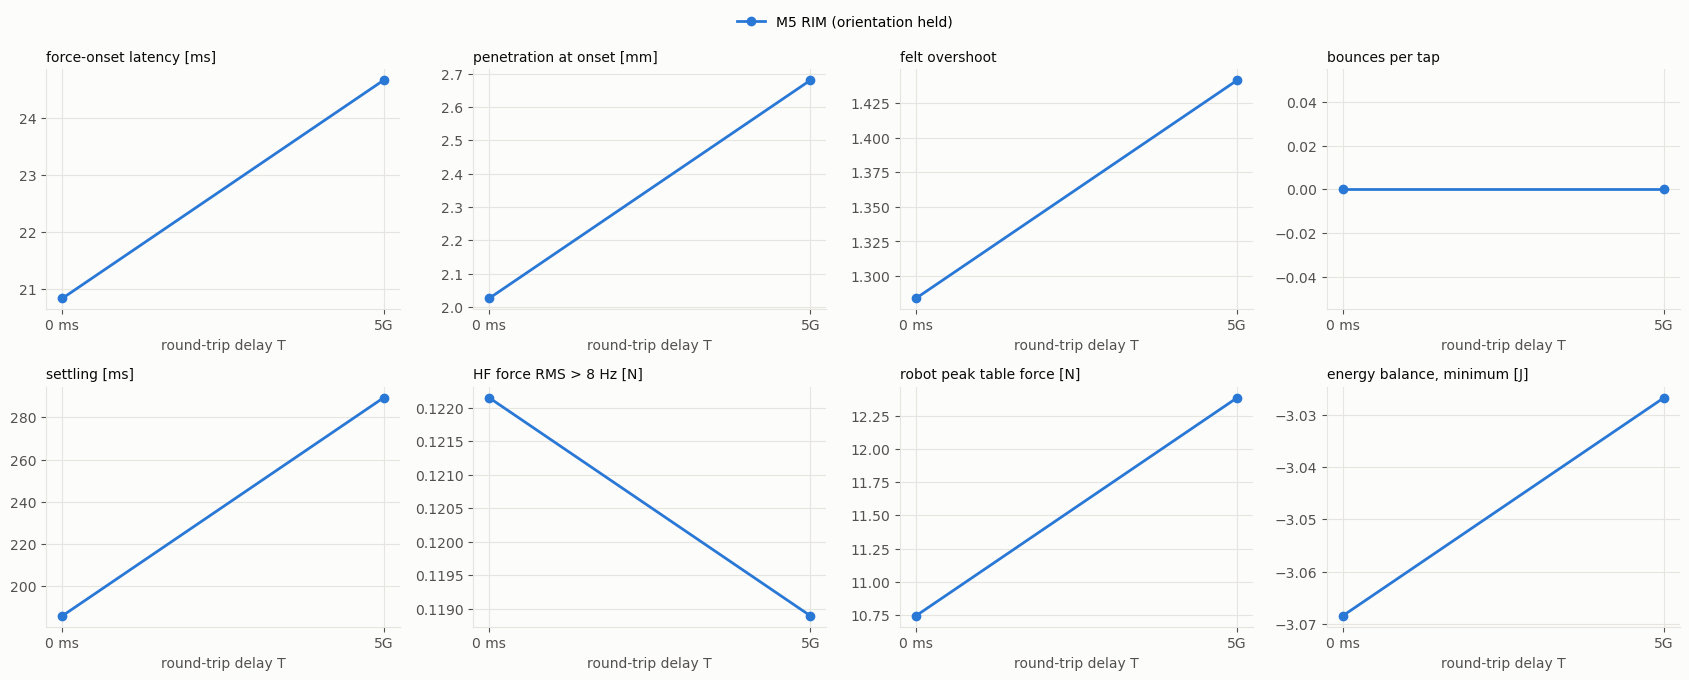

In [10]:
metrics = [
    ("onset_latency_ms_mean", "force-onset latency [ms]"),
    ("penetration_at_onset_mm_mean", "penetration at onset [mm]"),
    ("overshoot_mean", "felt overshoot"),
    ("bounces_mean", "bounces per tap"),
    ("settling_ms_mean", "settling [ms]"),
    ("hf_rms_N_mean", "HF force RMS > 8 Hz [N]"),
    ("robot_peak_table_N_mean", "robot peak table force [N]"),
    ("E_min_J", "energy balance, minimum [J]"),
]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, (y, title) in zip(axes.ravel(), metrics):
    P.by_delay(ax, df, y, label_methods=(ax is axes[0, 0]))
    ax.set_title(title, loc="left", fontsize=10)
fig.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()